Đây là chương trình huấn luyện nông nghiệp

In [1]:
print("hello")

hello


In [ ]:
Bước 1: Kết nối với Google Drive và khai báo thư viện
Bước này giúp cấp quyền cho Colab lưu file mô hình AI vào Google Drive của bạn.

In [1]:
# Ô code 1: Kết nối Drive và nạp thư viện
from google.colab import drive
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
import os

# Yêu cầu quyền truy cập Google Drive
drive.mount('/content/drive')

print("Phiên bản TensorFlow:", tf.__version__)

Mounted at /content/drive
Phiên bản TensorFlow: 2.21.0


Bước 2: Tải dữ liệu nông nghiệp từ Internet
Để demo, chúng ta dùng tập dữ liệu phân loại 5 loại thực vật có sẵn của Google. Dữ liệu sẽ được tự động tải về và chia thành tập huấn luyện (training) và tập kiểm tra (validation).

In [12]:
# Ô code 2: Tải và chuẩn bị dữ liệu
import pathlib
import tensorflow as tf

dataset_url = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"
data_dir = tf.keras.utils.get_file('flower_photos', origin=dataset_url, untar=True)
data_dir = pathlib.Path(data_dir)

# Tìm chính xác thư mục chứa các thư mục con loài hoa
# Đôi khi cấu trúc giải nén có thể bị lồng nhau
if (data_dir / 'flower_photos').exists():
    data_dir = data_dir / 'flower_photos'

batch_size = 32
img_height = 160
img_width = 160

# Tạo tập dữ liệu học (80% dữ liệu)
train_ds = tf.keras.utils.image_dataset_from_directory(
  data_dir,
  validation_split=0.2,
  subset="training",
  seed=123,
  image_size=(img_height, img_width),
  batch_size=batch_size)

# Tạo tập dữ liệu kiểm tra (20% dữ liệu)
val_ds = tf.keras.utils.image_dataset_from_directory(
  data_dir,
  validation_split=0.2,
  subset="validation",
  seed=123,
  image_size=(img_height, img_width),
  batch_size=batch_size)

class_names = train_ds.class_names
print("Các nhãn thực vật AI sẽ học:", class_names)

Found 3670 files belonging to 5 classes.
Using 2936 files for training.
Found 3670 files belonging to 5 classes.
Using 734 files for validation.
Các nhãn thực vật AI sẽ học: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']


Bước 3: Xây dựng và Huấn luyện mô hình (AI Learning)
Chúng ta sẽ sử dụng một kỹ thuật gọi là Transfer Learning (Học chuyển giao) với mô hình MobileNetV2. Cách này giúp AI học cực kỳ nhanh, độ chính xác cao mà không cần máy tính quá mạnh.

In [13]:
# Ô code 3: Xây dựng và huấn luyện AI
# Sử dụng bộ não AI đã được đào tạo sẵn (MobileNetV2)
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(img_height, img_width, 3),
    include_top=False,
    weights='imagenet'
)
base_model.trainable = False # Giữ nguyên kiến thức nền

# Gắn thêm các lớp mới để học nhận diện 5 loại hoa
model = tf.keras.Sequential([
  tf.keras.layers.Rescaling(1./127.5, offset=-1), # Chuẩn hóa ảnh về khoảng [-1, 1]
  base_model,
  tf.keras.layers.GlobalAveragePooling2D(),
  tf.keras.layers.Dense(len(class_names), activation='softmax')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

print("Bắt đầu cho AI học (Huấn luyện)...")
history = model.fit(train_ds, validation_data=val_ds, epochs=3)

Bắt đầu cho AI học (Huấn luyện)...
Epoch 1/3
92/92 ━━━━━━━━━━━━━━━━━━━━ 23s 176ms/step - accuracy: 0.7061 - loss: 0.8052 - val_accuracy: 0.8392 - val_loss: 0.4688
Epoch 2/3
92/92 ━━━━━━━━━━━━━━━━━━━━ 6s 70ms/step - accuracy: 0.8818 - loss: 0.3615 - val_accuracy: 0.8692 - val_loss: 0.3903
Epoch 3/3
92/92 ━━━━━━━━━━━━━━━━━━━━ 5s 53ms/step - accuracy: 0.9097 - loss: 0.2714 - val_accuracy: 0.8801 - val_loss: 0.3584


Bước 4: Lưu bộ não AI vào Google Drive
Lưu trữ mô hình dưới dạng file .h5. Bạn có thể tải file này về máy tính cá nhân ở nhà, hoặc mang sang bất kỳ máy nào có cài Python để sử dụng lại mà không cần huấn luyện lại từ đầu.

In [14]:
# Ô code 4: Lưu mô hình
model_path = '/content/drive/MyDrive/nong_nghiep_model.h5'
model.save(model_path)
print(f"✅ Đã lưu thành công mô hình AI tại: {model_path}")

✅ Đã lưu thành công mô hình AI tại: /content/drive/MyDrive/nong_nghiep_model.h5


Bước 5: Trực quan hóa kết quả cho Sinh viên
Đây là phần sinh viên nông nghiệp sẽ thích nhất. Đoạn code này sẽ tải mô hình bạn vừa lưu, lấy một vài bức ảnh ngẫu nhiên, cho AI đoán và in kết quả ra màn hình với hình ảnh trực quan.

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step


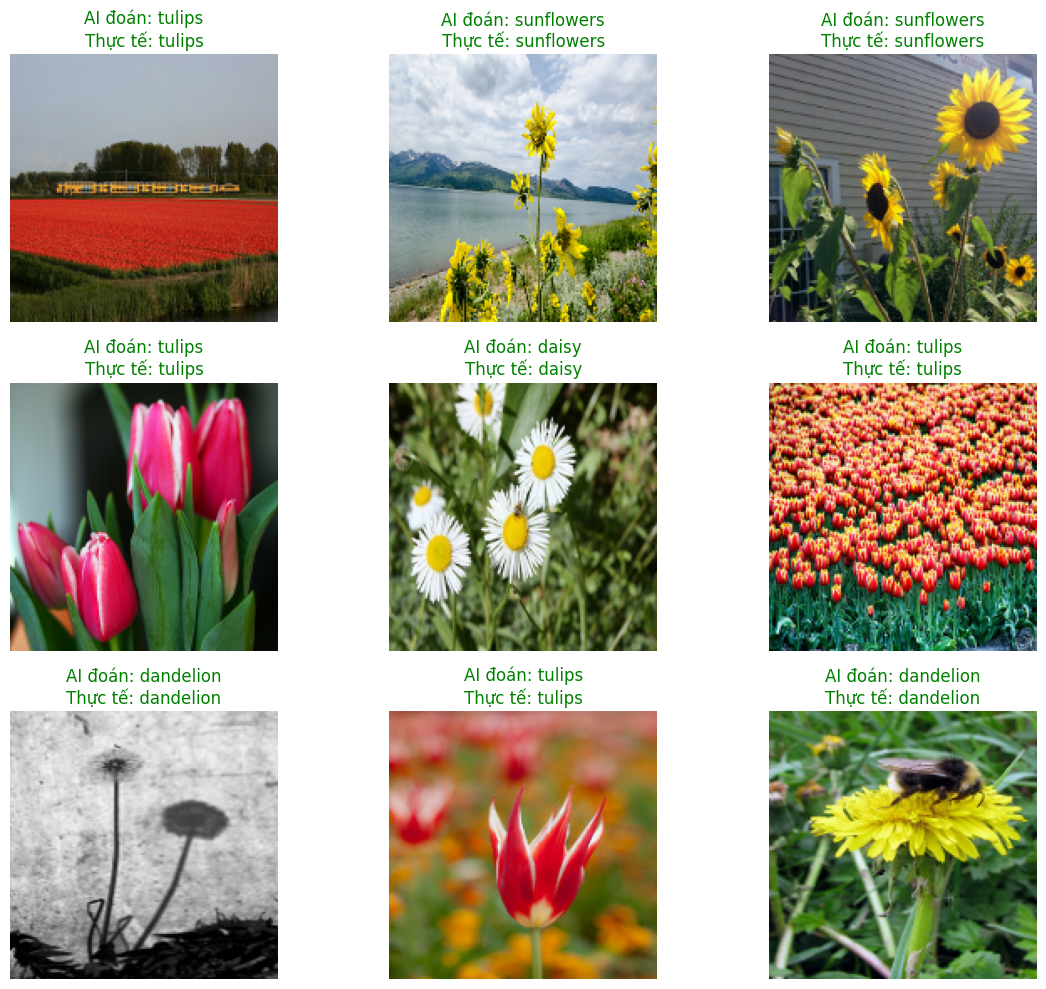

In [15]:
# Ô code 5: Tải mô hình và nhận diện hình ảnh thực tế
# Nạp lại bộ não AI từ Drive (Giả lập việc bạn dùng mô hình ở một máy khác)
loaded_model = tf.keras.models.load_model(model_path)

# Lấy 1 lô hình ảnh để kiểm tra
plt.figure(figsize=(12, 10))
for images, labels in val_ds.take(1):
  # Cho AI dự đoán
  predictions = loaded_model.predict(images)

  # Hiển thị 9 tấm ảnh đầu tiên kèm kết quả
  for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(images[i].numpy().astype("uint8"))

    # Lấy kết quả AI đoán cao nhất
    predicted_class = class_names[np.argmax(predictions[i])]
    actual_class = class_names[labels[i]]

    # Đổi màu chữ: Đoán đúng màu xanh, đoán sai màu đỏ
    color = 'green' if predicted_class == actual_class else 'red'

    plt.title(f"AI đoán: {predicted_class}\nThực tế: {actual_class}", color=color, fontsize=12)
    plt.axis("off")

plt.tight_layout()
plt.show()

Cách thay bằng dữ liệu nông nghiệp thực tế của bạn:
Thay vì dùng link tải của Google ở Bước 2, bạn chỉ cần nén các hình ảnh của bạn thành 1 file .zip (bên trong chia thành các thư mục như Benh_Gia_Suong_Mai, Benh_Dom_La, La_Khoe_Manh), tải lên Google Drive, sau đó dùng lệnh !unzip /content/drive/MyDrive/du_lieu_cua_toi.zip giải nén vào Colab và truyền đường dẫn thư mục đó vào biến data_dir.